Motaz elmashaleh sec2 1260067 

In [1]:

import numpy as np 
import matplotlib.pyplot as plt 
import tensorflow as tf 
from tensorflow import keras 
from keras import layers 

In [3]:
fashion_mnist = keras.datasets.fashion_mnist.load_data()

(X_train_full, y_train_full), (X_test, y_test) = fashion_mnist

In [4]:
X_train, y_train = X_train_full[5000:], y_train_full[5000:]
X_valid, y_valid = X_train_full[:5000], y_train_full[:5000]

In [5]:
print(X_train.shape)
print(X_valid.shape)
print(X_test.shape)

(55000, 28, 28)
(5000, 28, 28)
(10000, 28, 28)


In [6]:
class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

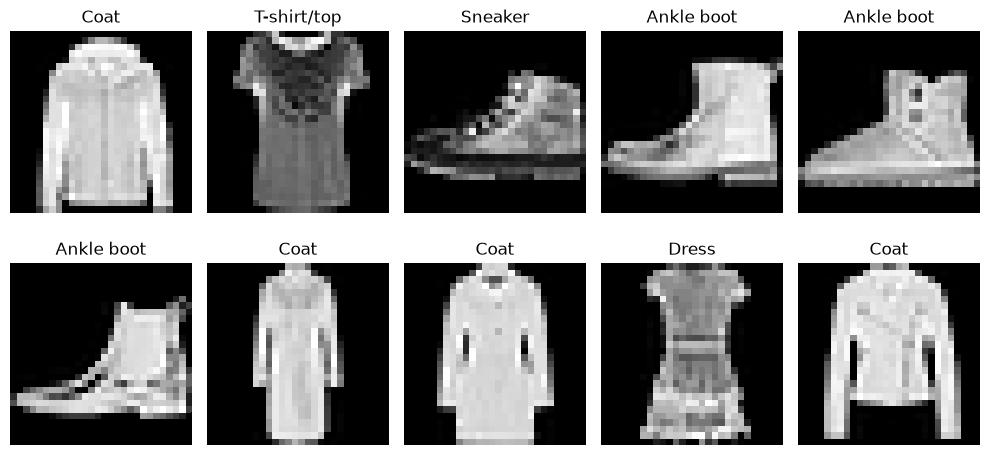

In [7]:
plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(class_names[y_train[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [8]:
print("Minimum pixel value:", X_train.min())
print("Maximum pixel value:", X_train.max())

Minimum pixel value: 0
Maximum pixel value: 255


In [9]:
X_train = X_train.astype("float32") / 255.0
X_valid = X_valid.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

In [10]:
print(X_train.min())
print(X_train.max())

0.0
1.0


In [11]:
model = keras.Sequential([
    layers.Flatten(input_shape=[28, 28]),
    layers.Dense(300, activation="relu"),
    layers.Dense(100, activation="relu"),
    layers.Dense(10, activation="softmax")
])

C:\Users\masha\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [12]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten (Flatten)                    │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 300)                 │         235,500 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 100)                 │          30,100 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 10)                  │           1,010 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 266,610 (1.02 MB)

 Trainable params: 266,610 (1.02 MB)

 Non-trainable params: 0 (0.00 B)

In [13]:
model.compile(
    loss="sparse_categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)

In [14]:
history = model.fit(
    X_train,
    y_train,
    epochs=30,
    validation_data=(X_valid, y_valid)
)

Epoch 1/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 33s 17ms/step - accuracy: 0.8272 - loss: 0.4825 - val_accuracy: 0.8406 - val_loss: 0.4400
Epoch 2/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 36s 21ms/step - accuracy: 0.8668 - loss: 0.3612 - val_accuracy: 0.8650 - val_loss: 0.3668
Epoch 3/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 31s 18ms/step - accuracy: 0.8771 - loss: 0.3283 - val_accuracy: 0.8856 - val_loss: 0.3215
Epoch 4/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 26s 15ms/step - accuracy: 0.8876 - loss: 0.3054 - val_accuracy: 0.8850 - val_loss: 0.3245
Epoch 5/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 29s 17ms/step - accuracy: 0.8936 - loss: 0.2860 - val_accuracy: 0.8836 - val_loss: 0.3168
Epoch 6/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 37s 15ms/step - accuracy: 0.8986 - loss: 0.2709 - val_accuracy: 0.8878 - val_loss: 0.2979
Epoch 7/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 40s 14ms/step - accuracy: 0.9025 - loss: 0.2599 - val_accuracy: 0.8932 - val_loss: 0.3018
Epoch 8/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 44s 15ms/step - accuracy: 0.9068 -

In [15]:
model.evaluate(X_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8807 - loss: 0.5124


[0.5124000906944275, 0.8806999921798706]

In [16]:
X_new = X_test[:3]
y_proba = model.predict(X_new)
y_proba.round(2)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 167ms/step


array([[0., 0., 0., 0., 0., 0., 0., 0., 0., 1.],
       [0., 0., 1., 0., 0., 0., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0., 0., 0., 0., 0., 0.]], dtype=float32)

In [17]:
y_pred = np.argmax(y_proba, axis=1)
print(y_pred)

[9 2 1]


In [18]:
y_proba_all = model.predict(X_test)
y_pred_all = np.argmax(y_proba_all, axis=1)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


In [19]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_all))

              precision    recall  f1-score   support

           0       0.84      0.83      0.84      1000
           1       0.98      0.97      0.98      1000
           2       0.82      0.72      0.77      1000
           3       0.85      0.92      0.88      1000
           4       0.70      0.90      0.79      1000
           5       0.97      0.96      0.97      1000
           6       0.77      0.60      0.68      1000
           7       0.93      0.97      0.95      1000
           8       0.97      0.98      0.98      1000
           9       0.97      0.95      0.96      1000

    accuracy                           0.88     10000
   macro avg       0.88      0.88      0.88     10000
weighted avg       0.88      0.88      0.88     10000



In [20]:
from sklearn.metrics import precision_score, recall_score, f1_score

precision = precision_score(y_test, y_pred_all, average="macro")
recall = recall_score(y_test, y_pred_all, average="macro")
f1 = f1_score(y_test, y_pred_all, average="macro")

print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)

Precision: 0.8827237239631112
Recall: 0.8806999999999998
F1 Score: 0.8790390664194019


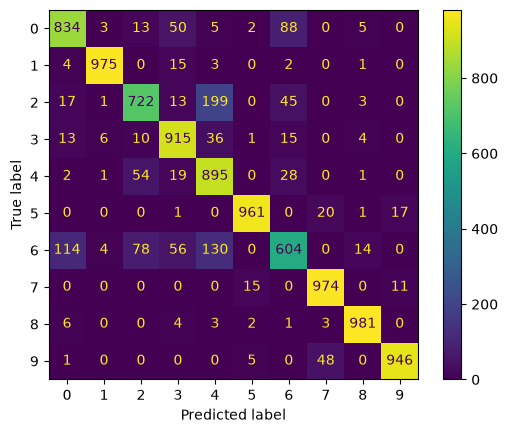

In [21]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_all)
plt.show()

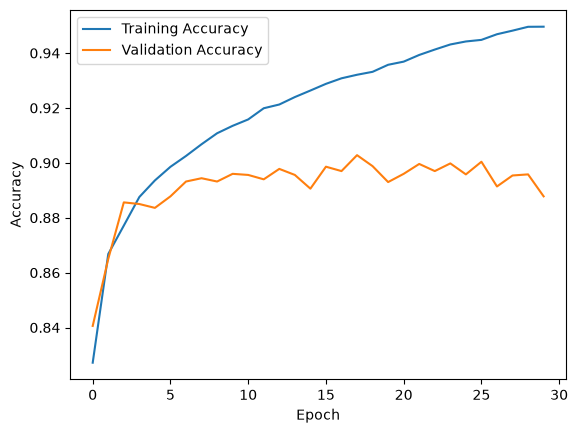

In [22]:
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

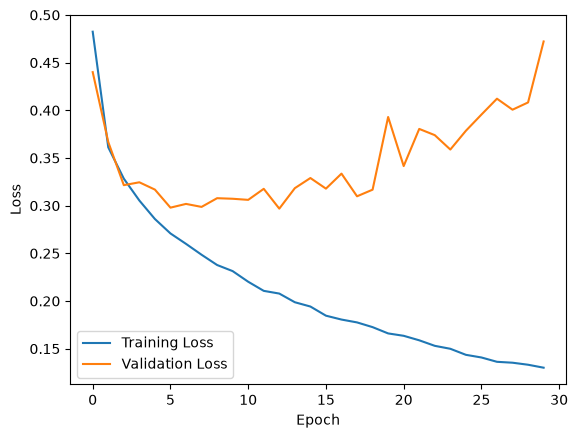

In [23]:
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

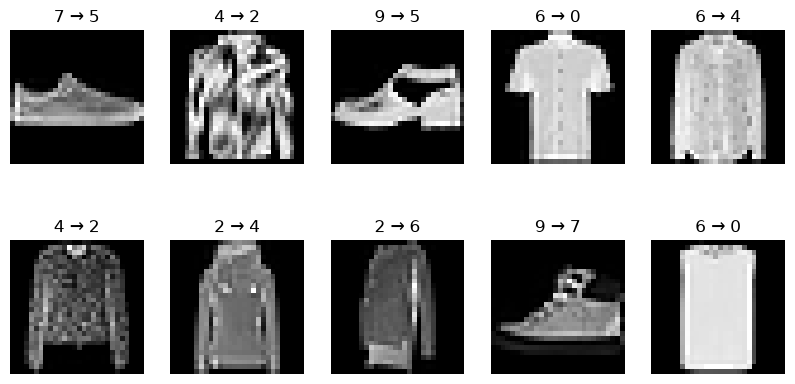

In [24]:
wrong = np.where(y_pred_all != y_test)[0][:10]

plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[wrong[i]], cmap="gray")
    plt.title(f"{y_test[wrong[i]]} → {y_pred_all[wrong[i]]}")
    plt.axis("off")

plt.show()

In [25]:
model_exp1 = keras.Sequential([
    layers.Flatten(input_shape=[28, 28]),
    layers.Dense(400, activation="relu"),
    layers.Dense(200, activation="relu"),
    layers.Dense(10, activation="softmax")
])

C:\Users\masha\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [26]:
model_exp1.compile(
    loss="sparse_categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)

In [27]:
history_exp1 = model_exp1.fit(
    X_train,
    y_train,
    epochs=30,
    validation_data=(X_valid, y_valid)
)

Epoch 1/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 39s 21ms/step - accuracy: 0.8272 - loss: 0.4749 - val_accuracy: 0.8530 - val_loss: 0.4003
Epoch 2/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 35s 20ms/step - accuracy: 0.8673 - loss: 0.3592 - val_accuracy: 0.8750 - val_loss: 0.3486
Epoch 3/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 35s 17ms/step - accuracy: 0.8801 - loss: 0.3236 - val_accuracy: 0.8734 - val_loss: 0.3339
Epoch 4/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 44s 19ms/step - accuracy: 0.8883 - loss: 0.3007 - val_accuracy: 0.8858 - val_loss: 0.3059
Epoch 5/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 30s 18ms/step - accuracy: 0.8943 - loss: 0.2827 - val_accuracy: 0.8826 - val_loss: 0.3259
Epoch 6/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 40s 23ms/step - accuracy: 0.9005 - loss: 0.2661 - val_accuracy: 0.8874 - val_loss: 0.3106
Epoch 7/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 32s 19ms/step - accuracy: 0.9057 - loss: 0.2511 - val_accuracy: 0.8888 - val_loss: 0.3018
Epoch 8/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 36s 21ms/step - accuracy: 0.9077 -

In [33]:
exp1_loss, exp1_accuracy = model_exp1.evaluate(X_test, y_test)

y_proba_exp1 = model_exp1.predict(X_test)
y_pred_exp1 = np.argmax(y_proba_exp1, axis=1)

exp1_precision = precision_score(y_test, y_pred_exp1, average="macro")
exp1_recall = recall_score(y_test, y_pred_exp1, average="macro")
exp1_f1 = f1_score(y_test, y_pred_exp1, average="macro")

print("Accuracy:", exp1_accuracy)
print("Precision:", exp1_precision)
print("Recall:", exp1_recall)
print("F1 Score:", exp1_f1)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8875 - loss: 0.5138
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Accuracy: 0.887499988079071
Precision: 0.8889966642440033
Recall: 0.8875
F1 Score: 0.8878110601319223


In [34]:
model_exp2 = keras.Sequential([
    layers.Flatten(input_shape=[28, 28]),
    layers.Dense(300, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(100, activation="relu"),
    layers.Dropout(0.25),
    layers.Dense(10, activation="softmax")
])

C:\Users\masha\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [35]:
model_exp2.compile(
    loss="sparse_categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)

In [36]:
model_exp2.compile(
    loss="sparse_categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)

In [37]:
history_exp2 = model_exp2.fit(
    X_train,
    y_train,
    epochs=30,
    validation_data=(X_valid, y_valid)
)

Epoch 1/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 33s 18ms/step - accuracy: 0.7998 - loss: 0.5574 - val_accuracy: 0.8576 - val_loss: 0.3938
Epoch 2/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 32s 19ms/step - accuracy: 0.8485 - loss: 0.4171 - val_accuracy: 0.8732 - val_loss: 0.3570
Epoch 3/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 36s 16ms/step - accuracy: 0.8618 - loss: 0.3804 - val_accuracy: 0.8796 - val_loss: 0.3343
Epoch 4/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 32s 19ms/step - accuracy: 0.8666 - loss: 0.3624 - val_accuracy: 0.8686 - val_loss: 0.3477
Epoch 5/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 37s 16ms/step - accuracy: 0.8753 - loss: 0.3422 - val_accuracy: 0.8732 - val_loss: 0.3329
Epoch 6/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 45s 18ms/step - accuracy: 0.8776 - loss: 0.3300 - val_accuracy: 0.8794 - val_loss: 0.3352
Epoch 7/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 36s 15ms/step - accuracy: 0.8811 - loss: 0.3217 - val_accuracy: 0.8796 - val_loss: 0.3202
Epoch 8/30
1719/1719 ━━━━━━━━━━━━━━━━━━━━ 42s 16ms/step - accuracy: 0.8851 -

In [38]:
exp2_loss, exp2_accuracy = model_exp2.evaluate(X_test, y_test)

y_proba_exp2 = model_exp2.predict(X_test)
y_pred_exp2 = np.argmax(y_proba_exp2, axis=1)

exp2_precision = precision_score(y_test, y_pred_exp2, average="macro")
exp2_recall = recall_score(y_test, y_pred_exp2, average="macro")
exp2_f1 = f1_score(y_test, y_pred_exp2, average="macro")

print("Accuracy:", exp2_accuracy)
print("Precision:", exp2_precision)
print("Recall:", exp2_recall)
print("F1 Score:", exp2_f1)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8882 - loss: 0.3535
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Accuracy: 0.8881999850273132
Precision: 0.8886042474175829
Recall: 0.8882
F1 Score: 0.8869080360472349


Part 2 :Regerssion

In [39]:
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split

housing = fetch_california_housing()

In [40]:
X_train_full, X_test, y_train_full, y_test = train_test_split(
    housing.data,
    housing.target,
    test_size=0.2,
    random_state=42
)

In [41]:
X_train, X_valid, y_train, y_valid = train_test_split(
    X_train_full,
    y_train_full,
    random_state=42
)

In [42]:
print(X_train.shape)
print(X_valid.shape)
print(X_test.shape)

(12384, 8)
(4128, 8)
(4128, 8)


In [43]:
import pandas as pd

df = pd.DataFrame(housing.data, columns=housing.feature_names)
df["Target"] = housing.target

In [44]:
print("Number of samples:", housing.data.shape[0])
print("Number of features:", housing.data.shape[1])
print("Feature names:", housing.feature_names)

Number of samples: 20640
Number of features: 8
Feature names: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']


In [45]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Target
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [46]:
df.isnull().sum()

MedInc        0
HouseAge      0
AveRooms      0
AveBedrms     0
Population    0
AveOccup      0
Latitude      0
Longitude     0
Target        0
dtype: int64

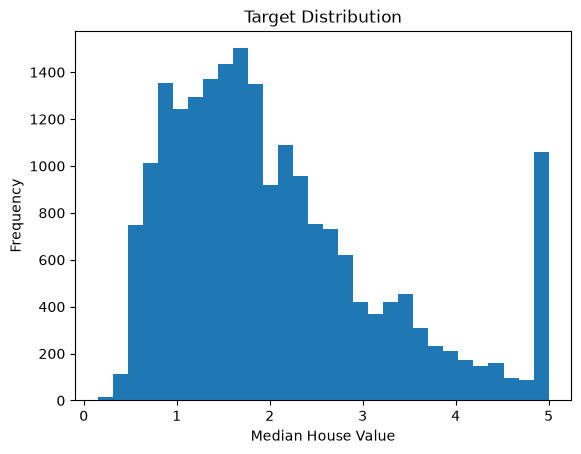

In [47]:
plt.hist(df["Target"], bins=30)

plt.xlabel("Median House Value")
plt.ylabel("Frequency")
plt.title("Target Distribution")

plt.show()

In [48]:
corr_matrix = df.corr()
corr_matrix

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Target
MedInc,1.000000,-0.119034,0.326895,-0.062040,0.004834,0.018766,-0.079809,-0.015176,0.688075
HouseAge,-0.119034,1.000000,-0.153277,-0.077747,-0.296244,0.013191,0.011173,-0.108197,0.105623
AveRooms,0.326895,-0.153277,1.000000,0.847621,-0.072213,-0.004852,0.106389,-0.027540,0.151948
AveBedrms,-0.062040,-0.077747,0.847621,1.000000,-0.066197,-0.006181,0.069721,0.013344,-0.046701
Population,0.004834,-0.296244,-0.072213,-0.066197,1.000000,0.069863,-0.108785,0.099773,-0.024650
AveOccup,0.018766,0.013191,-0.004852,-0.006181,0.069863,1.000000,0.002366,0.002476,-0.023737
Latitude,-0.079809,0.011173,0.106389,0.069721,-0.108785,0.002366,1.000000,-0.924664,-0.144160
Longitude,-0.015176,-0.108197,-0.027540,0.013344,0.099773,0.002476,-0.924664,1.000000,-0.045967
Target,0.688075,0.105623,0.151948,-0.046701,-0.024650,-0.023737,-0.144160,-0.045967,1.000000


In [49]:
corr_matrix["Target"].sort_values(ascending=False)

Target        1.000000
MedInc        0.688075
AveRooms      0.151948
HouseAge      0.105623
AveOccup     -0.023737
Population   -0.024650
Longitude    -0.045967
AveBedrms    -0.046701
Latitude     -0.144160
Name: Target, dtype: float64

In [50]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_valid = scaler.transform(X_valid)
X_test = scaler.transform(X_test)

In [51]:
model_reg = keras.Sequential([
    layers.Dense(64, activation="relu", input_shape=[X_train.shape[1]]),
    layers.Dense(32, activation="relu"),
    layers.Dense(16, activation="relu"),
    layers.Dense(1)
])

C:\Users\masha\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [52]:
model_reg.compile(
    loss="mse",
    optimizer="adam",
    metrics=["RootMeanSquaredError"]
)

In [53]:
history_reg = model_reg.fit(
    X_train,
    y_train,
    epochs=12,
    validation_data=(X_valid, y_valid)
)

Epoch 1/12
387/387 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - RootMeanSquaredError: 0.9126 - loss: 0.8328 - val_RootMeanSquaredError: 0.6673 - val_loss: 0.4453
Epoch 2/12
387/387 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - RootMeanSquaredError: 0.6273 - loss: 0.3935 - val_RootMeanSquaredError: 0.6427 - val_loss: 0.4131
Epoch 3/12
387/387 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - RootMeanSquaredError: 0.6003 - loss: 0.3603 - val_RootMeanSquaredError: 0.6114 - val_loss: 0.3738
Epoch 4/12
387/387 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - RootMeanSquaredError: 0.5944 - loss: 0.3533 - val_RootMeanSquaredError: 0.5903 - val_loss: 0.3485
Epoch 5/12
387/387 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - RootMeanSquaredError: 0.5788 - loss: 0.3350 - val_RootMeanSquaredError: 0.5847 - val_loss: 0.3419
Epoch 6/12
387/387 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - RootMeanSquaredError: 0.5705 - loss: 0.3255 - val_RootMeanSquaredError: 0.5746 - val_loss: 0.3302
Epoch 7/12
387/387 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - RootMeanSquaredError: 0.5616 - los

In [55]:
mse_test, rmse_test = model_reg.evaluate(X_test, y_test)

129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - RootMeanSquaredError: 0.5513 - loss: 0.3039


In [56]:
from sklearn.metrics import mean_absolute_error, r2_score

mse, rmse = model_reg.evaluate(X_test, y_test)

y_pred = model_reg.predict(X_test).flatten()

print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mse)
print("RMSE:", rmse)
print("R2:", r2_score(y_test, y_pred))

129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - RootMeanSquaredError: 0.5513 - loss: 0.3039
129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
MAE: 0.3742701815544565
MSE: 0.30388039350509644
RMSE: 0.5512534976005554
R2: 0.7681026419209227


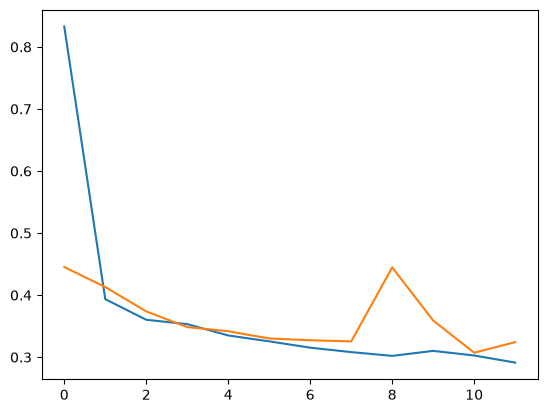

In [57]:
plt.plot(history_reg.history["loss"])
plt.plot(history_reg.history["val_loss"])
plt.show()

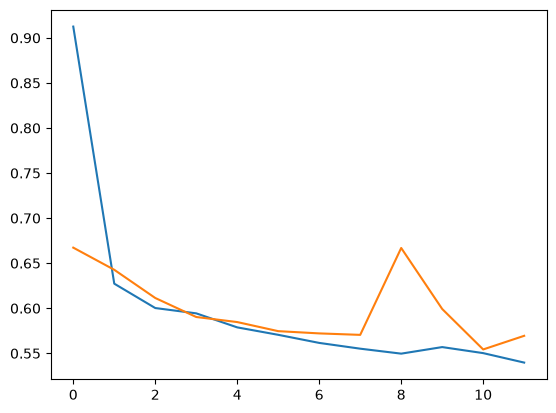

In [58]:
plt.plot(history_reg.history["RootMeanSquaredError"])
plt.plot(history_reg.history["val_RootMeanSquaredError"])
plt.show()

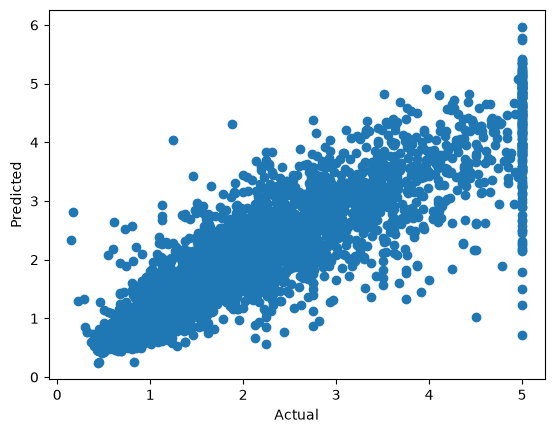

In [59]:
plt.scatter(y_test, y_pred)

plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.show()

In [60]:
model_reg_exp1 = keras.Sequential([
    layers.Dense(128, activation="relu", input_shape=[X_train.shape[1]]),
    layers.Dense(64, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(1)
])

C:\Users\masha\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [61]:
model_reg_exp1.compile(
    loss="mse",
    optimizer="adam",
    metrics=["RootMeanSquaredError"]
)

In [62]:
history_reg_exp1 = model_reg_exp1.fit(
    X_train,
    y_train,
    epochs=12,
    validation_data=(X_valid, y_valid)
)

Epoch 1/12
387/387 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - RootMeanSquaredError: 0.8974 - loss: 0.8053 - val_RootMeanSquaredError: 0.7038 - val_loss: 0.4953
Epoch 2/12
387/387 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - RootMeanSquaredError: 0.6230 - loss: 0.3882 - val_RootMeanSquaredError: 0.6278 - val_loss: 0.3942
Epoch 3/12
387/387 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - RootMeanSquaredError: 0.5930 - loss: 0.3517 - val_RootMeanSquaredError: 0.6006 - val_loss: 0.3607
Epoch 4/12
387/387 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - RootMeanSquaredError: 0.5795 - loss: 0.3359 - val_RootMeanSquaredError: 0.5998 - val_loss: 0.3598
Epoch 5/12
387/387 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - RootMeanSquaredError: 0.5688 - loss: 0.3236 - val_RootMeanSquaredError: 0.5998 - val_loss: 0.3598
Epoch 6/12
387/387 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - RootMeanSquaredError: 0.5588 - loss: 0.3122 - val_RootMeanSquaredError: 0.6298 - val_loss: 0.3966
Epoch 7/12
387/387 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - RootMeanSquaredError: 0.5600 - lo

In [63]:
mse1, rmse1 = model_reg_exp1.evaluate(X_test, y_test)

y_pred1 = model_reg_exp1.predict(X_test).flatten()

mae1 = mean_absolute_error(y_test, y_pred1)
r2_1 = r2_score(y_test, y_pred1)

print("MAE:", mae1)
print("MSE:", mse1)
print("RMSE:", rmse1)
print("R2:", r2_1)

129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - RootMeanSquaredError: 0.5539 - loss: 0.3068
129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
MAE: 0.3914412242687834
MSE: 0.3068453371524811
RMSE: 0.553936243057251
R2: 0.7658400333122137


In [64]:
model_reg_exp2 = keras.Sequential([
    layers.Dense(64, activation="relu", input_shape=[X_train.shape[1]]),
    layers.Dropout(0.2),
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(16, activation="relu"),
    layers.Dense(1)
])

C:\Users\masha\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [65]:
model_reg_exp2.compile(
    loss="mse",
    optimizer="adam",
    metrics=["RootMeanSquaredError"]
)

In [66]:
history_reg_exp2 = model_reg_exp2.fit(
    X_train,
    y_train,
    epochs=12,
    validation_data=(X_valid, y_valid)
)

Epoch 1/12
387/387 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - RootMeanSquaredError: 1.0161 - loss: 1.0326 - val_RootMeanSquaredError: 0.6886 - val_loss: 0.4742
Epoch 2/12
387/387 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - RootMeanSquaredError: 0.7422 - loss: 0.5509 - val_RootMeanSquaredError: 0.6562 - val_loss: 0.4307
Epoch 3/12
387/387 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - RootMeanSquaredError: 0.7096 - loss: 0.5035 - val_RootMeanSquaredError: 0.6261 - val_loss: 0.3920
Epoch 4/12
387/387 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - RootMeanSquaredError: 0.6798 - loss: 0.4622 - val_RootMeanSquaredError: 0.6265 - val_loss: 0.3925
Epoch 5/12
387/387 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - RootMeanSquaredError: 0.6600 - loss: 0.4356 - val_RootMeanSquaredError: 0.6267 - val_loss: 0.3927
Epoch 6/12
387/387 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - RootMeanSquaredError: 0.6491 - loss: 0.4214 - val_RootMeanSquaredError: 0.6097 - val_loss: 0.3718
Epoch 7/12
387/387 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - RootMeanSquaredError: 0.6351 - los

In [67]:
mse2, rmse2 = model_reg_exp2.evaluate(X_test, y_test)

y_pred2 = model_reg_exp2.predict(X_test).flatten()

mae2 = mean_absolute_error(y_test, y_pred2)
r2_2 = r2_score(y_test, y_pred2)

print("MAE:", mae2)
print("MSE:", mse2)
print("RMSE:", rmse2)
print("R2:", r2_2)

129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - RootMeanSquaredError: 0.5776 - loss: 0.3337
129/129 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
MAE: 0.3977650774645436
MSE: 0.3336574137210846
RMSE: 0.577630877494812
R2: 0.745379217137141


In [68]:
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

In [69]:
print("Baseline:", mae, mse, rmse, r2)
print("Experiment 1:", mae1, mse1, rmse1, r2_1)
print("Experiment 2:", mae2, mse2, rmse2, r2_2)

Baseline: 0.3742701815544565 0.30388039350509644 0.5512534976005554 0.7681026419209227
Experiment 1: 0.3914412242687834 0.3068453371524811 0.553936243057251 0.7658400333122137
Experiment 2: 0.3977650774645436 0.3336574137210846 0.577630877494812 0.745379217137141
